# Component 3 DDK - syllabic interval analysis

## 1. Environment Setup and Dependency Audit

In [32]:
# Imports and environment audit


from pathlib import Path
import copy
import json
import os
import re
import sys
import warnings
import importlib
import importlib.util

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

REQUIRED_PACKAGES = [
    'numpy', 'pandas', 'matplotlib', 'librosa', 'soundfile',
    'scipy', 'sklearn', 'joblib',
]
missing = [p for p in REQUIRED_PACKAGES if importlib.util.find_spec(p) is None]
if missing:
    raise ImportError(
        f'Missing packages: {missing}. '
        'Install them in the Anaconda kernel only after project-owner approval.'
    )

import librosa
import soundfile as sf
import scipy
import scipy.stats
import scipy.spatial.distance
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support,
    roc_auc_score, RocCurveDisplay,
)

print('Python:', sys.executable)
print('Python version:', sys.version.split()[0])
for pkg_name in ['numpy', 'pandas', 'matplotlib', 'librosa', 'soundfile', 'scipy', 'sklearn', 'joblib']:
    mod = importlib.import_module(pkg_name)
    print(f'  {pkg_name}: {getattr(mod, "__version__", "available")}')

if hasattr(scipy.spatial.distance, 'jensenshannon'):
    print('\nscipy.spatial.distance.jensenshannon: AVAILABLE')
else:
    raise ImportError('scipy.jensenshannon not available. Upgrade scipy >= 1.2.')

print()

Python: c:\Users\prasadxma\anaconda3\python.exe
Python version: 3.14.6
  numpy: 2.4.6
  pandas: 3.0.3
  matplotlib: 3.11.0
  librosa: 1.0.0
  soundfile: 0.14.0
  scipy: 1.18.0
  sklearn: 1.9.0
  joblib: 1.5.3

scipy.spatial.distance.jensenshannon: AVAILABLE



## 2. Project Root and Separate Output Paths


In [ ]:
# paths - new output dirs are separate from baseline


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'component3_ddk').is_dir() and (candidate / 'common').is_dir():
            return candidate
        nested = candidate / 'parkinson-speech-ai'
        if (nested / 'component3_ddk').is_dir() and (nested / 'common').is_dir():
            return nested
    raise FileNotFoundError('Could not locate parkinson-speech-ai root.')

REPO_ROOT = find_project_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_ROOT          = REPO_ROOT / 'data'
EXTRACTED_DATASET  = DATA_ROOT / 'Italian Parkinson_s Voice and speech'

# NEW: separate from baseline
RESULTS_DIR  = REPO_ROOT / 'results' / 'component3_ddk' / 'paper_inspired_syllabic'
MODELS_DIR   = REPO_ROOT / 'models' / 'component3_ddk_syllabic'
PERSONAL_DIR = RESULTS_DIR / 'personal_inference'

# Baseline paths: read-only reference; never overwritten
BASELINE_SPLIT_CSV    = REPO_ROOT / 'results' / 'component3_ddk' / 'ddk_participant_split.csv'
BASELINE_METRICS_JSON = REPO_ROOT / 'results' / 'component3_ddk' / 'ddk_heldout_metrics.json'
PERSONAL_DDK_DIR      = DATA_ROOT / 'personal_ddk'

print('Repository root:  ', REPO_ROOT)
print('Dataset:            ', EXTRACTED_DATASET)
print('New results dir:    ', RESULTS_DIR)
print('New models dir:    ', MODELS_DIR)
print('Personal infer dir: ', PERSONAL_DIR)
print('Baseline split CSV:', BASELINE_SPLIT_CSV)
print('Baseline metrics:', BASELINE_METRICS_JSON)

Repository root:   D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai
Dataset:             D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\data\Italian Parkinson_s Voice and speech
New results dir:     D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic
New models dir:     D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\models\component3_ddk_syllabic
Personal infer dir:  D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\personal_inference
Baseline split CSV: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\ddk_participant_split.csv
Baseline metrics: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\ddk_heldout_metrics.json


## 3. Dataset Discovery and Participant Identity

In [ ]:
# dataset discovery (same logic as baseline, self-contained)

GROUP_LABELS   = {'22 Elderly Healthy Control': 0, '28 People with Parkinson\'s disease': 1}
EXCLUDED_GROUP = '15 Young Healthy Control'
expected_groups = set(GROUP_LABELS) | {EXCLUDED_GROUP}

dataset_candidates = [
    EXTRACTED_DATASET,
    DATA_ROOT / 'Italian Parkinson_s Voice and speech',
    DATA_ROOT / 'raw' / 'Italian Parkinson_s Voice and speech',
    DATA_ROOT / 'raw' / "Italian Parkinson's Voice and speech",
]
DATASET_ROOT = next((p for p in dataset_candidates if p.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(f'Extracted dataset not found. Expected: {EXTRACTED_DATASET}')

wav_paths = sorted(
    p for p in DATASET_ROOT.rglob('*')
    if p.is_file() and p.suffix.lower() == '.wav'
    and p.name.upper().startswith(('D1', 'D2'))
)
if not wav_paths:
    raise FileNotFoundError('No D1/D2 WAV files found under dataset root.')

def group_for_path(path):
    parts = path.relative_to(DATASET_ROOT).parts
    for g in expected_groups:
        if g in parts:
            return g
    return None

discovery_rows = []
for path in wav_paths:
    group = group_for_path(path)
    if group is None:
        continue
    task = 'D1' if path.name.upper().startswith('D1') else 'D2'
    discovery_rows.append({
        'path': path,
        'relative_path': str(path.relative_to(DATASET_ROOT)),
        'group': group, 'task': task,
        'syllable': 'pa' if task == 'D1' else 'ta',
        'included': group in GROUP_LABELS,
    })

discovery_df = pd.DataFrame(discovery_rows)
print('All discovered recordings by group/task:')
display(discovery_df.groupby(['group', 'task']).size().unstack(fill_value=0))
print(f'Excluded {(~discovery_df["included"]).sum()} Young Healthy Control recordings')

All discovered recordings by group/task:


task,D1,D2
group,,
22 Elderly Healthy Control,22,22
28 People with Parkinson's disease,28,28


Excluded 0 Young Healthy Control recordings


In [ ]:
# conservative participant grouping (identical to baseline)


PD_RANGE_RE = re.compile(r'^\d+[-_]\d+$')
POSSIBLE_DUPLICATE_PD_NAMES = {'Nicola S', 'Roberto R', 'Vito S'}

def participant_metadata(path, group):
    participant_folder = path.parent.name
    parent_folder = path.parent.parent.name
    if group == "28 People with Parkinson's disease" and PD_RANGE_RE.match(parent_folder):
        identity_scope = parent_folder
        participant_id = f'ITA_PD_{identity_scope}_{participant_folder}'
        conservative_group_id = (
            f'ITA_PD_POSSIBLE_DUPLICATE_{participant_folder}'
            if participant_folder in POSSIBLE_DUPLICATE_PD_NAMES else participant_id
        )
    else:
        identity_scope = group
        participant_id = f'ITA_HC_{participant_folder}'
        conservative_group_id = participant_id
    return participant_folder, identity_scope, participant_id, conservative_group_id

model_df = discovery_df[discovery_df['included']].copy()
metadata_list = [
    participant_metadata(row.path, row.group)
    for row in model_df.itertuples(index=False)
]
model_df[['participant_folder', 'identity_scope', 'participant_id', 'conservative_group_id']] = (
    pd.DataFrame(metadata_list, index=model_df.index)
)
model_df['label'] = model_df['group'].map(GROUP_LABELS).astype(int)
model_df['label_name'] = model_df['label'].map({0: 'HC', 1: 'PD'})

structural_participant_table = (
    model_df[['participant_id', 'label', 'label_name', 'group', 'conservative_group_id']]
    .drop_duplicates('participant_id').sort_values('participant_id').reset_index(drop=True)
)
conservative_participant_table = (
    model_df[['conservative_group_id', 'label', 'label_name', 'group']]
    .drop_duplicates('conservative_group_id').sort_values('conservative_group_id').reset_index(drop=True)
)

print('Unique structural participants:    ', structural_participant_table['participant_id'].nunique())
print('Unique conservative eval groups:  ', conservative_participant_table['conservative_group_id'].nunique())
display(conservative_participant_table.groupby(['label_name', 'group']).size().rename('groups').reset_index())

Unique structural participants:     50
Unique conservative eval groups:   46


,label_name,group,groups
0,HC,22 Elderly Healthy Control,22
1,PD,28 People with Parkinson's disease,24


## 4. Paper-Inspired Syllabic Segmentation - TKEO Approach

In [ ]:
# TKEO segmentation utilities

MIN_ACTIVE_SEC  = 0.03   # 30 ms minimum for a valid syllabic burst
MIN_SILENCE_SEC = 0.02   # 20 ms minimum for a valid inter-syllabic gap
TKEO_SMOOTH_MS  = 10     # Hann-window smoothing window in ms
TKEO_THRESHOLD_PERCENTILE = 15  # adaptive threshold: 15th percentile of non-zero energy


def compute_tkeo(y):
    """Teager-Kaiser Energy Operator: psi[x(n)] = x(n)^2 - x(n-1)*x(n+1).

    Edge samples are set to the adjacent interior value.
    Returns non-negative energy array of same length as y.
    """
    if len(y) < 3:
        return np.zeros_like(y)
    tkeo = np.empty_like(y)
    tkeo[1:-1] = y[1:-1] ** 2 - y[:-2] * y[2:]
    tkeo[0] = tkeo[1]
    tkeo[-1] = tkeo[-2]
    return np.maximum(tkeo, 0.0)  # clamp negative floating-point artefacts


def smooth_tkeo(tkeo, sr, window_ms=TKEO_SMOOTH_MS):
    """Smooth TKEO energy with a Hann window to reduce frame-level noise."""
    window_samples = max(3, int(window_ms * sr / 1000))
    if window_samples % 2 == 0:
        window_samples += 1
    window = np.hanning(window_samples)
    window /= window.sum()
    return np.convolve(tkeo, window, mode='same')


def segment_by_tkeo(y, sr):
    """Segment a recording into speech-active and silence intervals using TKEO.

    Returns:
        active_intervals  : list of (start_s, end_s) for speech-active segments
        silence_intervals : list of (start_s, end_s) for inter-syllabic gaps
        tkeo_smooth       : smoothed TKEO array (for visualisation)
        threshold_value   : the adaptive threshold used
    """
    tkeo = compute_tkeo(y)
    tkeo_smooth = smooth_tkeo(tkeo, sr)

    nonzero = tkeo_smooth[tkeo_smooth > 0]
    if len(nonzero) == 0:
        return [], [], tkeo_smooth, 0.0
    threshold_value = np.percentile(nonzero, TKEO_THRESHOLD_PERCENTILE)
    is_active = tkeo_smooth > threshold_value

    changes = np.diff(is_active.astype(int))
    starts_on = np.where(changes == 1)[0] + 1
    ends_on   = np.where(changes == -1)[0] + 1
    if is_active[0]:
        starts_on = np.concatenate([[0], starts_on])
    if is_active[-1]:
        ends_on = np.concatenate([ends_on, [len(y)]])

    min_active_samples  = int(MIN_ACTIVE_SEC * sr)
    min_silence_samples = int(MIN_SILENCE_SEC * sr)

    active_intervals = [
        (s / sr, e / sr)
        for s, e in zip(starts_on, ends_on)
        if (e - s) >= min_active_samples
    ]
    silence_intervals = [
        (active_intervals[i-1][1], active_intervals[i][0])
        for i in range(1, len(active_intervals))
        if (active_intervals[i][0] - active_intervals[i-1][1]) >= MIN_SILENCE_SEC
    ]
    return active_intervals, silence_intervals, tkeo_smooth, threshold_value


print('TKEO segmentation utilities defined.')
print(f'  Min active interval:  {MIN_ACTIVE_SEC*1000:.0f} ms')
print(f'  Min silence interval: {MIN_SILENCE_SEC*1000:.0f} ms')
print(f'  TKEO smoothing:       {TKEO_SMOOTH_MS} ms Hann window')
print(f'  TKEO threshold:       {TKEO_THRESHOLD_PERCENTILE}th percentile of non-zero energy')

TKEO segmentation utilities defined.
  Min active interval:  30 ms
  Min silence interval: 20 ms
  TKEO smoothing:       10 ms Hann window
  TKEO threshold:       15th percentile of non-zero energy


## 5. Segmentation Visualisation on Example Recordings

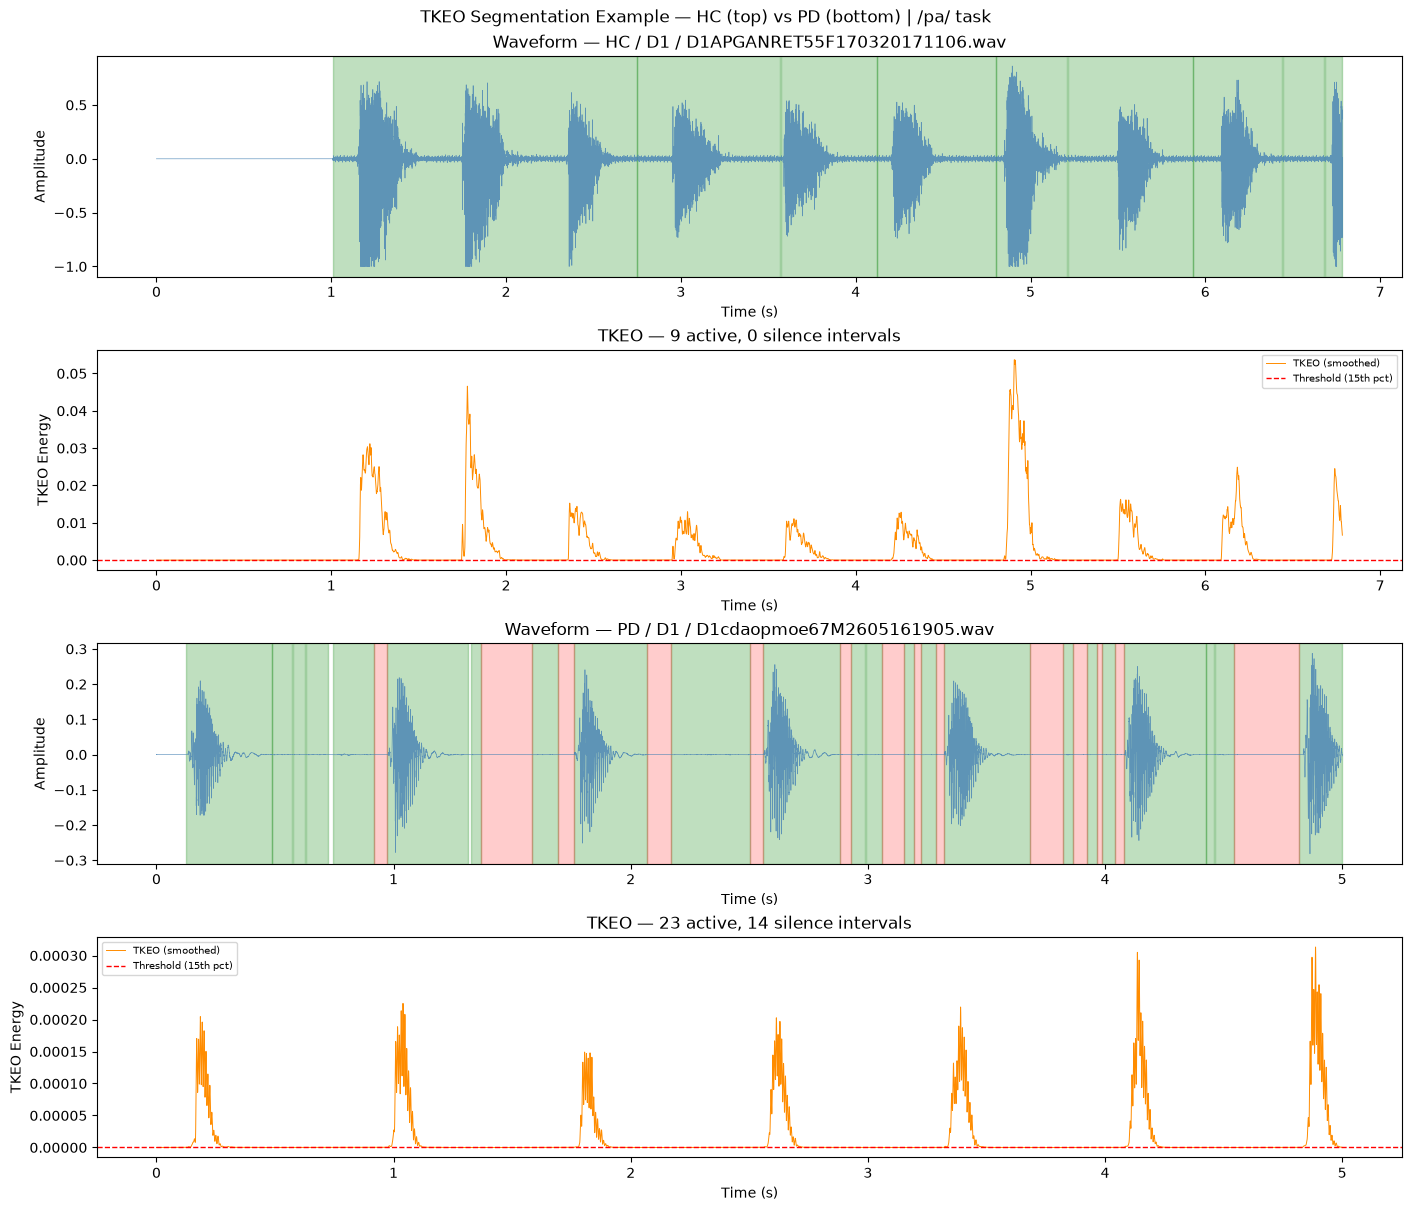

HC: {'file': 'D1APGANRET55F170320171106.wav', 'label': 'HC', 'task': 'D1', 'n_active': 9, 'n_silence': 0, 'threshold': np.float64(5.315453829406919e-06)}
PD: {'file': 'D1cdaopmoe67M2605161905.wav', 'label': 'PD', 'task': 'D1', 'n_active': 23, 'n_silence': 14, 'threshold': np.float64(2.107892588005707e-09)}

CAVEAT: Single-recording comparisons should not be interpreted as group differences.


In [ ]:
# visualise TKEO segmentation on one HC and one PD example

def visualise_segmentation(path, label_name, task, axes_pair):
    """Plot waveform + TKEO energy for one recording. Returns metadata dict."""
    y, sr = librosa.load(str(path), sr=None, mono=True)
    active_ivs, silence_ivs, tkeo_sm, thr = segment_by_tkeo(y, sr)
    t = np.linspace(0, len(y) / sr, len(y))
    ax1, ax2 = axes_pair

    ax1.plot(t, y, color='steelblue', lw=0.5, alpha=0.8)
    for s, e in active_ivs:
        ax1.axvspan(s, e, alpha=0.25, color='green')
    for s, e in silence_ivs:
        ax1.axvspan(s, e, alpha=0.20, color='red')
    ax1.set_title(f'Waveform — {label_name} / {task} / {Path(path).name}')
    ax1.set_ylabel('Amplitude'); ax1.set_xlabel('Time (s)')

    ax2.plot(t, tkeo_sm, color='darkorange', lw=0.7, label='TKEO (smoothed)')
    ax2.axhline(thr, color='red', ls='--', lw=1,
                label=f'Threshold ({TKEO_THRESHOLD_PERCENTILE}th pct)')
    ax2.set_title(f'TKEO — {len(active_ivs)} active, {len(silence_ivs)} silence intervals')
    ax2.set_ylabel('TKEO Energy'); ax2.set_xlabel('Time (s)')
    ax2.legend(fontsize=7)
    return {'file': Path(path).name, 'label': label_name, 'task': task,
            'n_active': len(active_ivs), 'n_silence': len(silence_ivs), 'threshold': thr}

hc_ex = model_df[(model_df['label'] == 0) & (model_df['task'] == 'D1')].iloc[0]
pd_ex = model_df[(model_df['label'] == 1) & (model_df['task'] == 'D1')].iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(14, 12), constrained_layout=True)
hc_info = visualise_segmentation(hc_ex['path'], 'HC', 'D1', [axes[0], axes[1]])
pd_info = visualise_segmentation(pd_ex['path'], 'PD', 'D1', [axes[2], axes[3]])
plt.suptitle('TKEO Segmentation Example — HC (top) vs PD (bottom) | /pa/ task', fontsize=12)
plt.show()
print('HC:', hc_info)
print('PD:', pd_info)
print()
print('CAVEAT: Single-recording comparisons should not be interpreted as group differences.')

## 6. Paper-Inspired Syllabic Interval Feature Extraction


In [ ]:
# Syllabic interval feature extraction function

MIN_INTERVALS_SKEW_KURT  = 4   # minimum for meaningful skewness/kurtosis
MIN_INTERVALS_NORMALTEST = 8   # minimum for D'Agostino-Pearson test
MIN_ACTIVE_INTERVALS     = 3   # minimum to compute any meaningful statistics

SYLLABIC_FEATURE_NAMES = [
    'n_active', 'active_mean', 'active_std', 'active_skew', 'active_kurt',
    'active_normaltest_stat', 'active_normaltest_p',
    'n_silence', 'silence_mean', 'silence_std', 'silence_skew', 'silence_kurt',
    'silence_normaltest_stat', 'silence_normaltest_p',
    'active_ratio', 'cv_active', 'cv_silence',
]
JSD_FEATURE_NAMES = ['jsd_active', 'jsd_silence']
ALL_SYLLABIC_FEATURE_NAMES = SYLLABIC_FEATURE_NAMES + JSD_FEATURE_NAMES


def _interval_stats(durations, label):
    """Compute descriptive statistics for a list of interval durations (seconds)."""
    n = len(durations)
    if n == 0:
        return {f'n_{label}': 0, f'{label}_mean': np.nan, f'{label}_std': np.nan,
                f'{label}_skew': np.nan, f'{label}_kurt': np.nan,
                f'{label}_normaltest_stat': np.nan, f'{label}_normaltest_p': np.nan}
    arr = np.array(durations)
    ddof = 1 if n > 1 else 0
    skew_val = float(scipy.stats.skew(arr))     if n >= MIN_INTERVALS_SKEW_KURT  else np.nan
    kurt_val = float(scipy.stats.kurtosis(arr)) if n >= MIN_INTERVALS_SKEW_KURT  else np.nan
    if n >= MIN_INTERVALS_NORMALTEST:
        s_stat, p_val = scipy.stats.normaltest(arr)
        s_stat, p_val = float(s_stat), float(p_val)
    else:
        s_stat = p_val = np.nan
    return {f'n_{label}': n,
            f'{label}_mean': float(np.mean(arr)), f'{label}_std': float(np.std(arr, ddof=ddof)),
            f'{label}_skew': skew_val, f'{label}_kurt': kurt_val,
            f'{label}_normaltest_stat': s_stat, f'{label}_normaltest_p': p_val}


def extract_syllabic_features(audio_path):
    """Extract paper-inspired syllabic interval features from one recording.

    Returns dict with SYLLABIC_FEATURE_NAMES keys, or None if too few active intervals.
    JSD features (jsd_active, jsd_silence) require a separately constructed HC reference
    and are NOT computed here.
    """
    y, sr = librosa.load(str(audio_path), sr=None, mono=True)
    duration_s = len(y) / sr
    active_ivs, silence_ivs, _, _ = segment_by_tkeo(y, sr)
    if len(active_ivs) < MIN_ACTIVE_INTERVALS:
        return None
    active_dur  = [e - s for s, e in active_ivs]
    silence_dur = [e - s for s, e in silence_ivs]
    feats = {}
    feats.update(_interval_stats(active_dur, 'active'))
    feats.update(_interval_stats(silence_dur, 'silence'))
    total_active = sum(active_dur)
    feats['active_ratio'] = float(total_active / duration_s) if duration_s > 0 else np.nan
    m_a, s_a = feats['active_mean'], feats['active_std']
    feats['cv_active'] = float(s_a / m_a) if (m_a and m_a > 0 and not np.isnan(s_a)) else np.nan
    m_s, s_s = feats['silence_mean'], feats['silence_std']
    feats['cv_silence'] = float(s_s / m_s) if (m_s and m_s > 0 and not np.isnan(s_s)) else np.nan
    return feats


print(f'Syllabic feature extractor defined.')
print(f'  Non-JSD features per recording: {len(SYLLABIC_FEATURE_NAMES)}')
print(f'  JSD features (added after HC reference): {len(JSD_FEATURE_NAMES)}')
print(f'  Total: {len(ALL_SYLLABIC_FEATURE_NAMES)}')

Syllabic feature extractor defined.
  Non-JSD features per recording: 17
  JSD features (added after HC reference): 2
  Total: 19


In [ ]:

# batch syllabic feature extraction

extraction_rows = []
syllabic_failures = []

for row in model_df.itertuples(index=False):
    try:
        feats = extract_syllabic_features(str(row.path))
    except Exception as exc:
        syllabic_failures.append({'relative_path': row.relative_path,
                                    'reason': f'{type(exc).__name__}: {exc}'})
        continue
    if feats is None:
        syllabic_failures.append({'relative_path': row.relative_path,
                                    'reason': f'Too few active intervals (< {MIN_ACTIVE_INTERVALS})'})
        continue
    record = dict(feats)
    record.update({
        'filename': row.relative_path, 'participant_id': row.participant_id,
        'conservative_group_id': row.conservative_group_id,
        'task': row.task, 'syllable': row.syllable,
        'label': int(row.label), 'label_name': row.label_name, 'group': row.group,
    })
    extraction_rows.append(record)

syllabic_df = pd.DataFrame(extraction_rows)
syllabic_failures_df = pd.DataFrame(syllabic_failures)
if syllabic_df.empty:
    raise RuntimeError('No recordings produced usable syllabic features.')

print(f'Feature rows: {len(syllabic_df)}')
print(f'Failures/skips: {len(syllabic_failures_df)}')
if not syllabic_failures_df.empty:
    display(syllabic_failures_df)
display(syllabic_df.groupby(['label_name', 'task']).size().unstack(fill_value=0))

Feature rows: 97
Failures/skips: 3


,relative_path,reason
0,22 Elderly Healthy Control\GILDA C\D1GCIALSDA5...,Too few active intervals (< 3)
1,22 Elderly Healthy Control\LISCO G\D2GLIIUSSC5...,Too few active intervals (< 3)
2,22 Elderly Healthy Control\VITANTONIO D\D1VDIE...,Too few active intervals (< 3)


task,D1,D2
label_name,,
HC,20,21
PD,28,28


## 7. Exploratory Analysis — Interval Distribution Plots


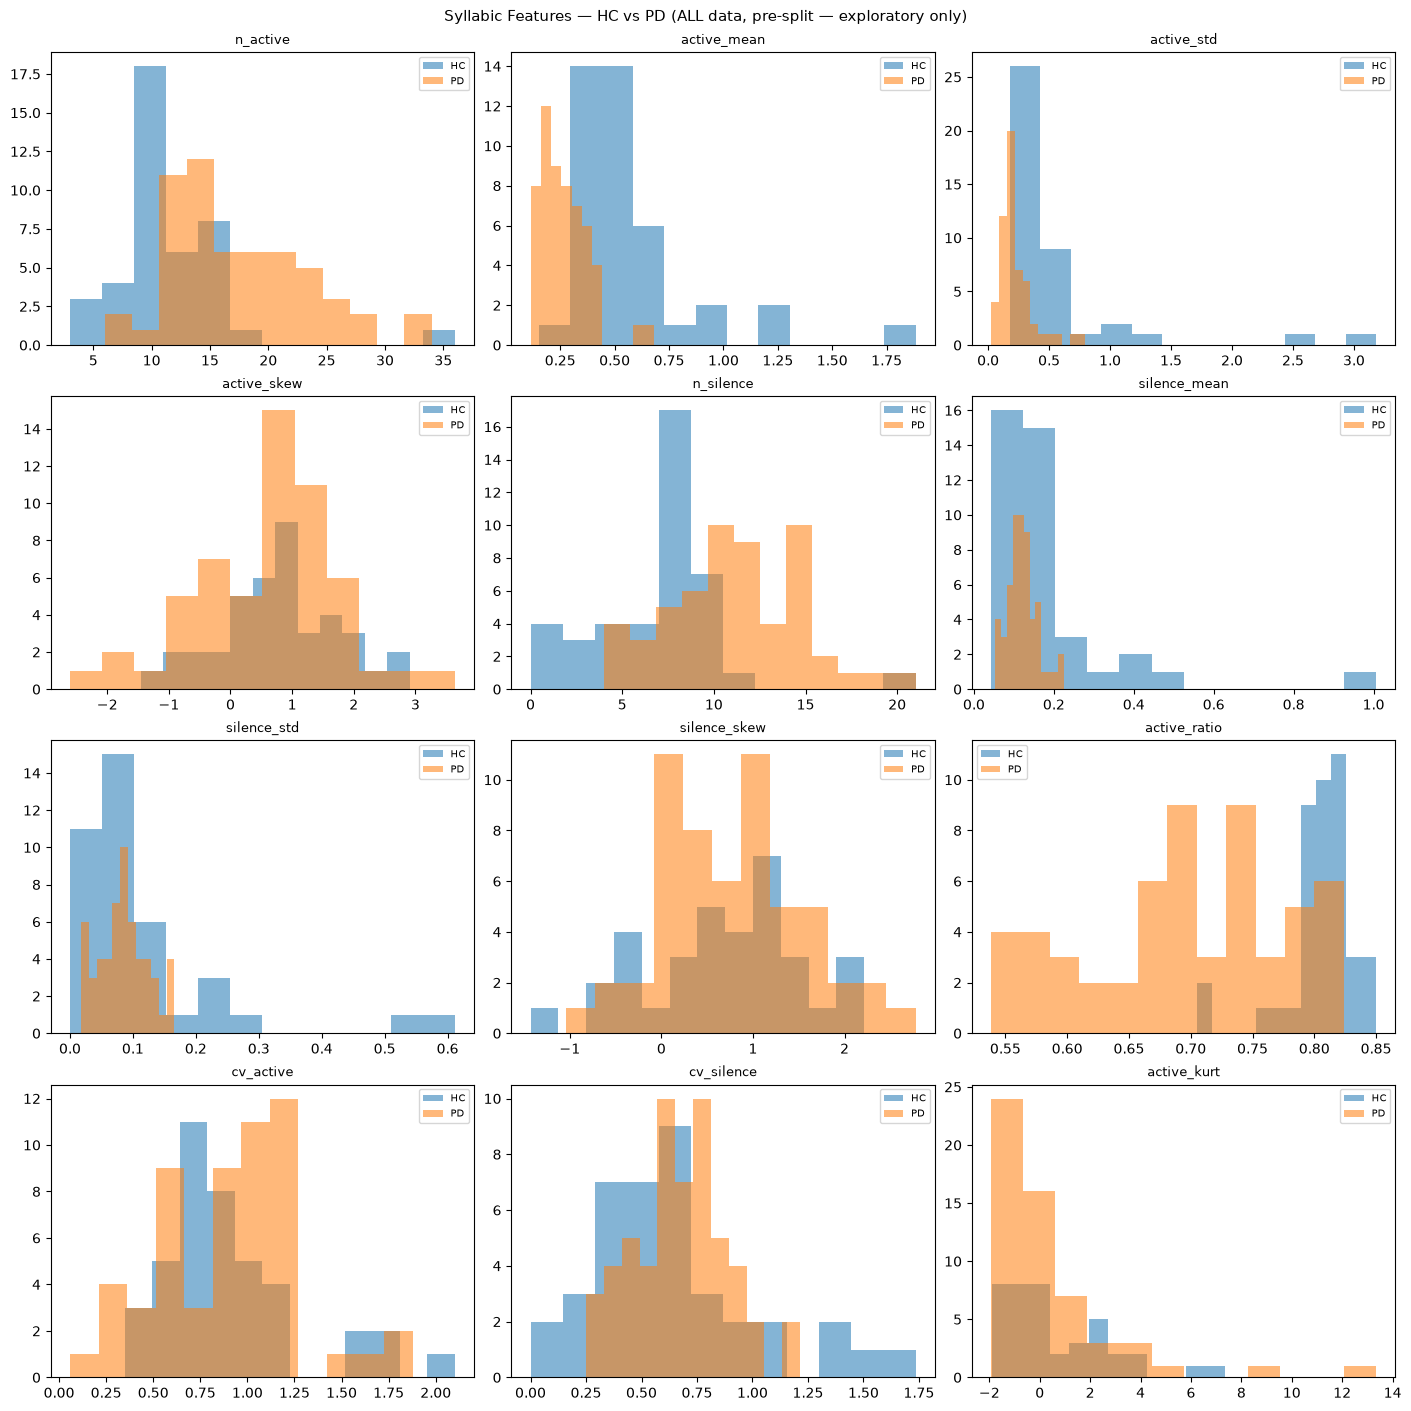

NOTE: These distributions include all participants (train + test).
They are for visual exploration only, not model evaluation.

Feature group means by label:


label_name,HC,PD
n_active,11.3171,17.1786
active_mean,0.5738,0.2695
active_std,0.5626,0.2306
active_skew,0.7901,0.6070
n_silence,6.7805,11.2500
silence_mean,0.1882,0.1223
silence_std,0.1128,0.0848
silence_skew,0.6647,0.7546
active_ratio,0.8055,0.6960
cv_active,0.9089,0.8983


In [ ]:
# EDA plots (pre-split, exploratory only)


EDA_FEATURES = [
    'n_active', 'active_mean', 'active_std', 'active_skew',
    'n_silence', 'silence_mean', 'silence_std', 'silence_skew',
    'active_ratio', 'cv_active', 'cv_silence', 'active_kurt',
]

fig, axes = plt.subplots(4, 3, figsize=(14, 14), constrained_layout=True)
for ax, feat in zip(axes.flat, EDA_FEATURES):
    for lname, subset in syllabic_df.groupby('label_name'):
        ax.hist(subset[feat].dropna(), alpha=0.55, bins=12, label=lname)
    ax.set_title(feat, fontsize=9)
    ax.legend(fontsize=7)
plt.suptitle('Syllabic Features — HC vs PD (ALL data, pre-split — exploratory only)', fontsize=11)
plt.show()

print('NOTE: These distributions include all participants (train + test).')
print('They are for visual exploration only, not model evaluation.')
print('\nFeature group means by label:')
display(syllabic_df.groupby('label_name')[EDA_FEATURES].mean().T.round(4))

In [ ]:
# missing/non-finite value audit

missing_counts    = syllabic_df[SYLLABIC_FEATURE_NAMES].isna().sum()
nonfinite_counts  = (~np.isfinite(syllabic_df[SYLLABIC_FEATURE_NAMES].astype(float))).sum()

print('Missing values per feature:')
display(missing_counts[missing_counts > 0] if missing_counts.any() else 'None')
print('\nNon-finite values per feature:')
display(nonfinite_counts[nonfinite_counts > 0] if nonfinite_counts.any() else 'None')

# Exclude features with > 50% missing (statistically unreliable)
high_missing = missing_counts[missing_counts > len(syllabic_df) * 0.5].index.tolist()
if high_missing:
    print(f'\nFeatures with >50% missing (excluded from modelling): {high_missing}')

CORE_MODELLING_FEATURES = [f for f in SYLLABIC_FEATURE_NAMES if f not in high_missing]
print(f'\nCore modelling features ({len(CORE_MODELLING_FEATURES)}): {CORE_MODELLING_FEATURES}')

Missing values per feature:


active_skew                 1
active_kurt                 1
active_normaltest_stat      8
active_normaltest_p         8
silence_mean                2
silence_std                 2
silence_skew                7
silence_kurt                7
silence_normaltest_stat    32
silence_normaltest_p       32
cv_silence                  2
dtype: int64


Non-finite values per feature:


active_skew                 1
active_kurt                 1
active_normaltest_stat      8
active_normaltest_p         8
silence_mean                2
silence_std                 2
silence_skew                7
silence_kurt                7
silence_normaltest_stat    32
silence_normaltest_p       32
cv_silence                  2
dtype: int64


Core modelling features (17): ['n_active', 'active_mean', 'active_std', 'active_skew', 'active_kurt', 'active_normaltest_stat', 'active_normaltest_p', 'n_silence', 'silence_mean', 'silence_std', 'silence_skew', 'silence_kurt', 'silence_normaltest_stat', 'silence_normaltest_p', 'active_ratio', 'cv_active', 'cv_silence']


## 8. Participant-Level Train/Test Split


In [ ]:
# Participant-level train and test split

RANDOM_STATE = 42
TEST_SIZE = 0.20

conservative_groups_avail = (
    syllabic_df[['conservative_group_id', 'label', 'label_name', 'group']]
    .drop_duplicates('conservative_group_id')
    .sort_values('conservative_group_id')
    .reset_index(drop=True)
)
if conservative_groups_avail['label'].nunique() < 2:
    raise ValueError('Both HC and PD groups required for stratified split.')

try:
    train_ids, test_ids = train_test_split(
        conservative_groups_avail['conservative_group_id'],
        test_size=TEST_SIZE, random_state=RANDOM_STATE,
        stratify=conservative_groups_avail['label'],
    )
except ValueError as exc:
    raise ValueError('Stratified participant split failed — cannot safely continue.') from exc

train_participants = set(train_ids)
test_participants  = set(test_ids)

if train_participants & test_participants:
    raise AssertionError('LEAKAGE: participant overlap between train and test!')

syllabic_df['split'] = np.where(
    syllabic_df['conservative_group_id'].isin(train_participants), 'train', 'test'
)
train_syl_df = syllabic_df[syllabic_df['split'] == 'train'].copy()
test_syl_df  = syllabic_df[syllabic_df['split'] == 'test'].copy()

if set(train_syl_df['label'].unique()) != {0, 1} or set(test_syl_df['label'].unique()) != {0, 1}:
    raise ValueError('Both HC and PD required in both training and test sets.')

# Cross-check with baseline split
if BASELINE_SPLIT_CSV.exists():
    base_split = pd.read_csv(BASELINE_SPLIT_CSV)
    base_train = set(base_split[base_split['split'] == 'train']['conservative_group_id'])
    base_test  = set(base_split[base_split['split'] == 'test']['conservative_group_id'])
    print(f'Groups matching baseline train: {len(train_participants & base_train)}/{len(base_train)}')
    print(f'Groups matching baseline test:  {len(test_participants & base_test)}/{len(base_test)}')
    novel_groups = (train_participants | test_participants) - base_train - base_test
    if novel_groups:
        print(f'Groups present in syllabic split but absent from baseline: {sorted(novel_groups)}')
        print('(These may be recordings that failed baseline extraction but succeeded here.)')

print(f'\nTraining groups: {len(train_participants)} | Test groups: {len(test_participants)}')
print(f'Training recordings: {len(train_syl_df)} | Test recordings: {len(test_syl_df)}')
display(syllabic_df.groupby(['split', 'label_name', 'task'])
        .agg(recordings=('filename', 'size'), groups=('conservative_group_id', 'nunique'))
        .reset_index())

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
syllabic_split_path = RESULTS_DIR / 'syllabic_participant_split.csv'
split_tbl = conservative_groups_avail.copy()
split_tbl['split'] = split_tbl['conservative_group_id'].map(
    lambda v: 'train' if v in train_participants else 'test'
)
split_tbl.to_csv(syllabic_split_path, index=False)
print('Syllabic split saved:', syllabic_split_path)

Groups matching baseline train: 36/36
Groups matching baseline test:  10/10

Training groups: 36 | Test groups: 10
Training recordings: 77 | Test recordings: 20


,split,label_name,task,recordings,groups
0,test,HC,D1,3,3
1,test,HC,D2,5,5
2,test,PD,D1,6,5
3,test,PD,D2,6,5
4,train,HC,D1,17,17
5,train,HC,D2,16,16
6,train,PD,D1,22,19
7,train,PD,D2,22,19


Syllabic split saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\syllabic_participant_split.csv


## 9. Jensen-Shannon Divergence (JSD) Feature Construction


In [ ]:
# JSD utilities and validation

JSD_BINS = 20
JSD_SMOOTHING = 1e-10


def build_hc_reference(hc_durations_list):
    """Build normalised histogram reference from HC interval durations.
    Returns (hist, bin_edges) or (None, None) if fewer than 2 intervals.
    """
    durations = np.array(hc_durations_list)
    if len(durations) < 2:
        return None, None
    d_max = durations.max() + 1e-9
    hist, bin_edges = np.histogram(durations, bins=JSD_BINS, range=(0.0, d_max))
    hist = hist.astype(float) + JSD_SMOOTHING
    hist /= hist.sum()
    return hist, bin_edges


def compute_jsd_vs_reference(durations, ref_hist, ref_bin_edges):
    """Compute Jensen-Shannon distance between one recording's duration distribution and HC reference.
    Returns float in [0, 1], or np.nan if insufficient data.
    Convention: scipy.spatial.distance.jensenshannon with base=2 returns sqrt(JSD).
    """
    if ref_hist is None or len(durations) < 2:
        return np.nan
    arr = np.clip(np.array(durations), ref_bin_edges[0], ref_bin_edges[-1] - 1e-12)
    hist_rec, _ = np.histogram(arr, bins=ref_bin_edges)
    hist_rec = hist_rec.astype(float) + JSD_SMOOTHING
    hist_rec /= hist_rec.sum()
    val = scipy.spatial.distance.jensenshannon(ref_hist, hist_rec, base=2.0)
    if not np.isfinite(val):
        return np.nan
    return max(0.0, float(val))


def collect_interval_durations(subset_df, interval_type='active'):
    """Re-extract raw interval durations from audio for all recordings in subset_df."""
    all_durations = []
    for row in subset_df.itertuples(index=False):
        path_col = model_df.loc[model_df['relative_path'] == row.filename, 'path']
        if path_col.empty:
            continue
        y, sr = librosa.load(str(path_col.values[0]), sr=None, mono=True)
        active_ivs, silence_ivs, _, _ = segment_by_tkeo(y, sr)
        ivs = active_ivs if interval_type == 'active' else silence_ivs
        all_durations.extend(e - s for s, e in ivs)
    return all_durations


def add_jsd_features(target_df, ref_ah, ref_ae, ref_sh, ref_se):
    """Add jsd_active and jsd_silence columns to target_df.
    Uses training-derived reference only (no leakage from target_df labels).
    """
    jsd_a, jsd_s = [], []
    for row in target_df.itertuples(index=False):
        path_col = model_df.loc[model_df['relative_path'] == row.filename, 'path']
        if path_col.empty:
            jsd_a.append(np.nan); jsd_s.append(np.nan); continue
        y, sr = librosa.load(str(path_col.values[0]), sr=None, mono=True)
        active_ivs, silence_ivs, _, _ = segment_by_tkeo(y, sr)
        jsd_a.append(compute_jsd_vs_reference([e-s for s,e in active_ivs],  ref_ah, ref_ae))
        jsd_s.append(compute_jsd_vs_reference([e-s for s,e in silence_ivs], ref_sh, ref_se))
    result = target_df.copy()
    result['jsd_active']  = jsd_a
    result['jsd_silence'] = jsd_s
    return result


# Validation
print('JSD Validation:')
_p = np.array([0.1, 0.2, 0.3, 0.25, 0.15]); _p /= _p.sum()
print(f'  Identical distributions JSD = {scipy.spatial.distance.jensenshannon(_p, _p, base=2.0):.6f} (expected ~0)')
_q = np.array([0.9, 0.05, 0.03, 0.01, 0.01]); _q /= _q.sum()
_jsd_diff = scipy.spatial.distance.jensenshannon(_p, _q, base=2.0)
print(f'  Different distributions JSD = {_jsd_diff:.4f} (expected > 0, <= 1)')
print(f'  JSD in [0,1]: {"PASS" if 0 <= _jsd_diff <= 1 else "FAIL"}')
_rng_durations = list(np.random.RandomState(0).exponential(0.1, 100))
_h, _e = build_hc_reference(_rng_durations)
assert abs(_h.sum() - 1.0) < 1e-9
print(f'  HC reference sums to 1: PASS')
print('All JSD validation checks passed.')

JSD Validation:
  Identical distributions JSD = 0.000000 (expected ~0)
  Different distributions JSD = 0.7384 (expected > 0, <= 1)
  JSD in [0,1]: PASS
  HC reference sums to 1: PASS
All JSD validation checks passed.


In [ ]:
# build HC reference from training HC only, then add JSD features

print('Building HC reference distributions from training HC participants...')
train_hc_df = train_syl_df[train_syl_df['label'] == 0]
print(f'  Training HC recordings: {len(train_hc_df)}')

hc_active_dur  = collect_interval_durations(train_hc_df, 'active')
hc_silence_dur = collect_interval_durations(train_hc_df, 'silence')

ref_ah, ref_ae = build_hc_reference(hc_active_dur)
ref_sh, ref_se = build_hc_reference(hc_silence_dur)

print(f'  HC active intervals pooled:  {len(hc_active_dur)}')
print(f'  HC silence intervals pooled: {len(hc_silence_dur)}')

print('Adding JSD features to training set...')
train_syl_df = add_jsd_features(train_syl_df, ref_ah, ref_ae, ref_sh, ref_se)
# print('Adding JSD features to test set (training reference only — no leakage)...')
test_syl_df  = add_jsd_features(test_syl_df,  ref_ah, ref_ae, ref_sh, ref_se)

print('\nJSD feature summary (training set):')
display(train_syl_df.groupby('label_name')[['jsd_active', 'jsd_silence']].describe())

Building HC reference distributions from training HC participants...
  Training HC recordings: 33
  HC active intervals pooled:  395
  HC silence intervals pooled: 245
Adding JSD features to training set...

JSD feature summary (training set):


jsd_active                                                    \
                count      mean       std       min       25%       50%   
label_name                                                                
HC               33.0  0.469705  0.116518  0.333314  0.373784  0.437622   
PD               44.0  0.508999  0.122974  0.290545  0.415550  0.490993   

                               jsd_silence                                \
                 75%       max       count      mean       std       min   
label_name                                                                 
HC          0.523188  0.767967        31.0  0.521698  0.131482  0.321064   
PD          0.583647  0.788698        44.0  0.454188  0.083197  0.306244   

                                                    
                 25%       50%       75%       max  
label_name                                          
HC          0.431567  0.509574  0.597240  0.825103  
PD          0.382767  0.460371  0.525553  0.618591

HC reference bundle saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\models\component3_ddk_syllabic\hc_reference_distributions.joblib


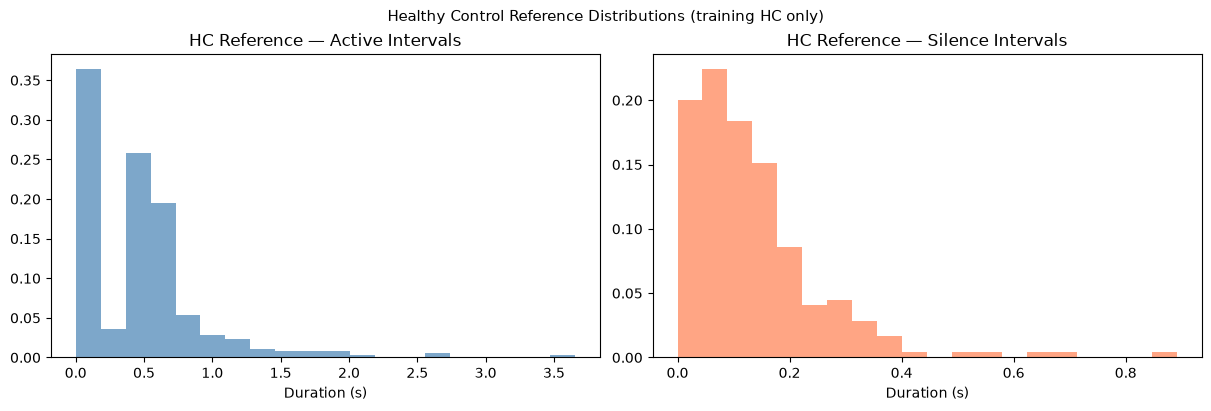

Reference plot saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\hc_reference_distributions.png


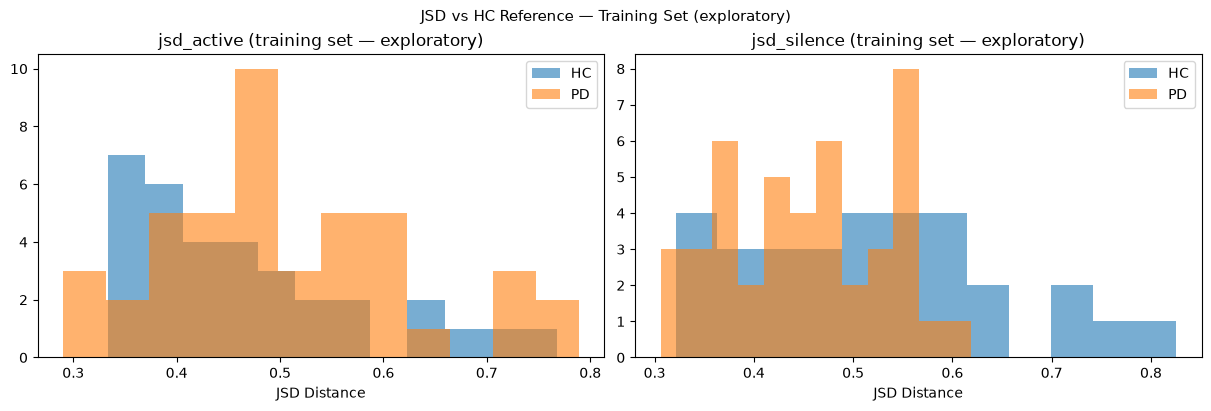

In [ ]:
# Save HC reference artifacts and visualise

MODELS_DIR.mkdir(parents=True, exist_ok=True)
hc_reference_path = MODELS_DIR / 'hc_reference_distributions.joblib'
hc_ref_bundle = {
    'ref_active_hist': ref_ah, 'ref_active_edges': ref_ae,
    'ref_silence_hist': ref_sh, 'ref_silence_edges': ref_se,
    'n_hc_active':  len(hc_active_dur),
    'n_hc_silence': len(hc_silence_dur),
    'n_hc_train_recordings': int(len(train_hc_df)),
    'jsd_bins': JSD_BINS, 'jsd_smoothing': JSD_SMOOTHING,
    'jsd_convention': 'scipy.spatial.distance.jensenshannon(base=2) — returns sqrt(JSD)',
    'source': 'training HC participants only (no leakage)',
}
joblib.dump(hc_ref_bundle, hc_reference_path)
print('HC reference bundle saved:', hc_reference_path)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
if ref_ah is not None:
    bc_a = (ref_ae[:-1] + ref_ae[1:]) / 2
    axes[0].bar(bc_a, ref_ah, width=np.diff(ref_ae), alpha=0.7, color='steelblue')
    axes[0].set_title('HC Reference — Active Intervals'); axes[0].set_xlabel('Duration (s)')
if ref_sh is not None:
    bc_s = (ref_se[:-1] + ref_se[1:]) / 2
    axes[1].bar(bc_s, ref_sh, width=np.diff(ref_se), alpha=0.7, color='coral')
    axes[1].set_title('HC Reference — Silence Intervals'); axes[1].set_xlabel('Duration (s)')
plt.suptitle('Healthy Control Reference Distributions (training HC only)', fontsize=11)
plt.show()
ref_plot_path = RESULTS_DIR / 'hc_reference_distributions.png'
fig.savefig(ref_plot_path, dpi=120, bbox_inches='tight')
print('Reference plot saved:', ref_plot_path)

# JSD distribution comparison (training set, exploratory)
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, feat in zip(axes2, ['jsd_active', 'jsd_silence']):
    for lname, subset in train_syl_df.groupby('label_name'):
        ax.hist(subset[feat].dropna(), alpha=0.6, bins=12, label=lname)
    ax.set_title(f'{feat} (training set — exploratory)'); ax.set_xlabel('JSD Distance'); ax.legend()
plt.suptitle('JSD vs HC Reference — Training Set (exploratory)', fontsize=11)
plt.show()

In [ ]:
# final feature table preparation

FINAL_FEATURE_NAMES = CORE_MODELLING_FEATURES + JSD_FEATURE_NAMES

def get_valid_rows(df, feature_names):
    fm = df[feature_names].astype(float)
    mask = fm.notna().all(axis=1) & np.isfinite(fm).all(axis=1)
    n_drop = (~mask).sum()
    if n_drop:
        print(f'  Dropped {n_drop} rows with missing/non-finite features')
    return df.loc[mask].reset_index(drop=True)

print('Filtering training set...')
train_valid = get_valid_rows(train_syl_df, FINAL_FEATURE_NAMES)
print('Filtering test set...')
test_valid  = get_valid_rows(test_syl_df,  FINAL_FEATURE_NAMES)

if set(train_valid['label'].unique()) != {0, 1} or set(test_valid['label'].unique()) != {0, 1}:
    raise ValueError('Both HC and PD required in training and test after filtering.')

X_train = train_valid[FINAL_FEATURE_NAMES].astype(float)
y_train = train_valid['label']
groups_train = train_valid['conservative_group_id']
X_test  = test_valid[FINAL_FEATURE_NAMES].astype(float)
y_test  = test_valid['label']

print(f'Training: {len(X_train)} recordings | {train_valid["conservative_group_id"].nunique()} groups')
print(f'Test:     {len(X_test)} recordings  | {test_valid["conservative_group_id"].nunique()} groups')
print(f'Feature names ({len(FINAL_FEATURE_NAMES)}): {FINAL_FEATURE_NAMES}')

feature_table_path = RESULTS_DIR / 'syllabic_ddk_features.csv'
pd.concat([train_syl_df, test_syl_df]).to_csv(feature_table_path, index=False)
print('Feature table saved:', feature_table_path)

Filtering training set...
  Dropped 23 rows with missing/non-finite features
Filtering test set...
  Dropped 9 rows with missing/non-finite features
Training: 54 recordings | 31 groups
Test:     11 recordings  | 5 groups
Feature names (19): ['n_active', 'active_mean', 'active_std', 'active_skew', 'active_kurt', 'active_normaltest_stat', 'active_normaltest_p', 'n_silence', 'silence_mean', 'silence_std', 'silence_skew', 'silence_kurt', 'silence_normaltest_stat', 'silence_normaltest_p', 'active_ratio', 'cv_active', 'cv_silence', 'jsd_active', 'jsd_silence']
Feature table saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\syllabic_ddk_features.csv


## 10. Training-Only Grouped Cross-Validation


In [ ]:
# training-only repeated grouped cross-validation

CV_SPLITS = 5
CV_REPETITIONS = 3
CV_SEEDS = [42, 123, 999]

CANDIDATES = {
    'random_forest': RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced'),
    'svm_rbf': Pipeline([
        ('sc', StandardScaler()),
        ('svm', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    'logistic_regression': Pipeline([
        ('sc', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
}

# Filter training data to base features (no JSD) for fold-internal JSD computation
train_base_valid = get_valid_rows(train_syl_df, CORE_MODELLING_FEATURES)
X_base = train_base_valid[CORE_MODELLING_FEATURES].astype(float)
y_base = train_base_valid['label']
g_base = train_base_valid['conservative_group_id']

n_hc = (train_base_valid[['conservative_group_id','label']].drop_duplicates().query('label==0').shape[0])
n_pd = (train_base_valid[['conservative_group_id','label']].drop_duplicates().query('label==1').shape[0])
print(f'Training groups for CV: HC={n_hc}, PD={n_pd}')

cv_summary = {}
cv_skip_reasons = []

if n_hc >= CV_SPLITS and n_pd >= CV_SPLITS:
    print(f'Running {CV_REPETITIONS}x{CV_SPLITS}-fold grouped CV (with per-fold JSD)...')
    print('This is computationally intensive — extracting audio per fold.')
    cv_scores = {name: [] for name in CANDIDATES}

    for rep, seed in enumerate(CV_SEEDS[:CV_REPETITIONS]):
        sgkf = StratifiedGroupKFold(n_splits=CV_SPLITS, shuffle=True, random_state=seed)
        folds = list(sgkf.split(X_base, y_base, groups=g_base))

        folds_ok = True
        for fi, (tr_i, va_i) in enumerate(folds):
            if set(y_base.iloc[tr_i]) != {0,1} or set(y_base.iloc[va_i]) != {0,1}:
                cv_skip_reasons.append(f'Rep{rep+1} fold{fi+1}: missing class'); folds_ok = False
            if set(g_base.iloc[tr_i]) & set(g_base.iloc[va_i]):
                cv_skip_reasons.append(f'Rep{rep+1} fold{fi+1}: group overlap'); folds_ok = False
        if not folds_ok:
            continue

        for fi, (tr_i, va_i) in enumerate(folds):
            fold_tr = train_base_valid.iloc[tr_i]
            fold_va = train_base_valid.iloc[va_i]

            # Build fold-specific JSD reference from fold-train HC only
            fold_hc_tr = fold_tr[fold_tr['label'] == 0]
            fold_a_ref, fold_ae_ref = build_hc_reference(
                collect_interval_durations(fold_hc_tr, 'active'))
            fold_s_ref, fold_se_ref = build_hc_reference(
                collect_interval_durations(fold_hc_tr, 'silence'))

            fold_tr_jsd = add_jsd_features(fold_tr, fold_a_ref, fold_ae_ref, fold_s_ref, fold_se_ref)
            fold_va_jsd = add_jsd_features(fold_va, fold_a_ref, fold_ae_ref, fold_s_ref, fold_se_ref)

            Xft = get_valid_rows(fold_tr_jsd, FINAL_FEATURE_NAMES)
            Xfv = get_valid_rows(fold_va_jsd, FINAL_FEATURE_NAMES)
            if Xft.empty or Xfv.empty:
                cv_skip_reasons.append(f'Rep{rep+1} fold{fi+1}: empty after JSD filter')
                continue
            if set(Xft['label']) != {0,1} or set(Xfv['label']) != {0,1}:
                cv_skip_reasons.append(f'Rep{rep+1} fold{fi+1}: missing class after JSD')
                continue

            for clf_name, clf in CANDIDATES.items():
                clf_c = copy.deepcopy(clf)
                clf_c.fit(Xft[FINAL_FEATURE_NAMES].astype(float), Xft['label'])
                acc = accuracy_score(Xfv['label'], clf_c.predict(Xfv[FINAL_FEATURE_NAMES].astype(float)))
                cv_scores[clf_name].append(float(acc))

    for name, scores in cv_scores.items():
        if scores:
            cv_summary[name] = {
                'fold_accuracies': scores, 'mean_accuracy': float(np.mean(scores)),
                'std_accuracy': float(np.std(scores)), 'n_folds': len(scores)
            }
        else:
            cv_summary[name] = {'status': 'no valid folds'}

    cv_df = pd.DataFrame({
        k: {'mean_acc': v.get('mean_accuracy', np.nan),
            'std_acc':  v.get('std_accuracy',  np.nan),
            'n_folds':  v.get('n_folds', 0)}
        for k, v in cv_summary.items()
    }).T
    print('\nTraining-only CV results (syllabic features):')
    display(cv_df)
else:
    cv_skip_reasons.append(f'Insufficient training groups: HC={n_hc}, PD={n_pd} < {CV_SPLITS}')
    cv_summary = {'status': 'skipped', 'reason': cv_skip_reasons}
    print('CV skipped:', cv_skip_reasons)

if cv_skip_reasons:
    print('\nCV warnings:', cv_skip_reasons)

  Dropped 23 rows with missing/non-finite features
Training groups for CV: HC=13, PD=18
Running 3x5-fold grouped CV (with per-fold JSD)...
This is computationally intensive — extracting audio per fold.

Training-only CV results (syllabic features):


,mean_acc,std_acc,n_folds
random_forest,0.866667,0.132227,15.0
svm_rbf,0.833333,0.100887,15.0
logistic_regression,0.852121,0.109013,15.0


## 11. Train Primary Model on Full Training Set

Primary model fitted on 54 training recordings.


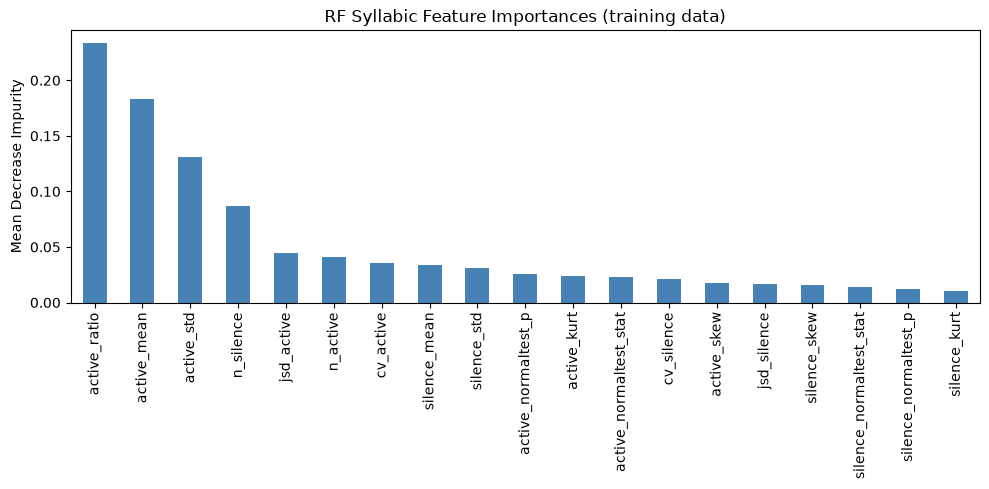

Feature importance plot saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\syllabic_feature_importance.png


In [ ]:
# Train primary Random Forest on full training set

primary_clf = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced'
)
primary_clf.fit(X_train, y_train)
print(f'Primary model fitted on {len(X_train)} training recordings.')

importances = pd.Series(primary_clf.feature_importances_, index=FINAL_FEATURE_NAMES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
importances.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('RF Syllabic Feature Importances (training data)')
ax.set_ylabel('Mean Decrease Impurity')
plt.tight_layout(); plt.show()
fi_path = RESULTS_DIR / 'syllabic_feature_importance.png'
fig.savefig(fi_path, dpi=120, bbox_inches='tight')
print('Feature importance plot saved:', fi_path)

## 12. Held-Out Test Evaluation

Held-out test results — syllabic features (Random Forest):


,evaluation,participants,recordings,accuracy,precision_PD,sensitivity_recall_PD,specificity_HC,f1_PD,roc_auc
0,held_out_test_recording_syllabic,5,11,1.0,1.0,1.0,1.0,1.0,1.0
1,held_out_test_participant_syllabic,5,11,1.0,1.0,1.0,1.0,1.0,1.0



Classification report (recording level):
              precision    recall  f1-score   support

          HC       1.00      1.00      1.00         1
          PD       1.00      1.00      1.00        10

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



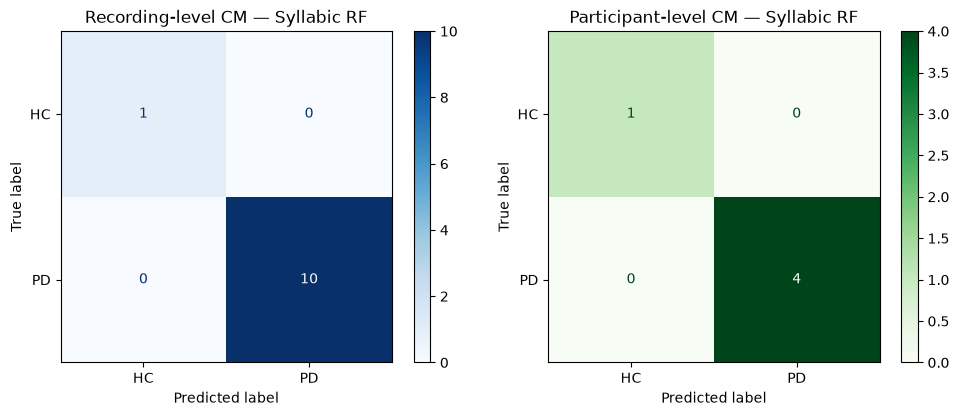

Confusion matrix saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\syllabic_confusion_matrix.png


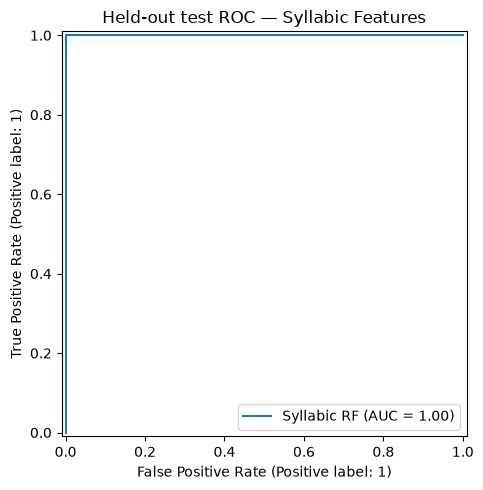

ROC curve saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\syllabic_roc_curve.png

Note: Training and CV metrics are NOT held-out test performance.


In [ ]:
# Evaluation utilities and held-out test metrics


def evaluate_model(model, X_eval, y_eval, n_participants, label):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1] if hasattr(model, 'predict_proba') else None
    cm   = confusion_matrix(y_eval, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    prec, rec, f1, _ = precision_recall_fscore_support(y_eval, pred, labels=[0,1], zero_division=0)
    auc = float(roc_auc_score(y_eval, prob)) if prob is not None and y_eval.nunique() == 2 else None
    return {
        'evaluation': label, 'participants': int(n_participants), 'recordings': int(len(y_eval)),
        'accuracy': float(accuracy_score(y_eval, pred)),
        'precision_PD': float(prec[1]), 'sensitivity_recall_PD': float(rec[1]),
        'specificity_HC': float(tn/(tn+fp)) if (tn+fp) > 0 else None,
        'f1_PD': float(f1[1]), 'roc_auc': auc,
        'confusion_matrix_hc_pd': cm.tolist(),
        'classification_report': classification_report(
            y_eval, pred, labels=[0,1], target_names=['HC','PD'],
            output_dict=True, zero_division=0),
    }, pred, prob, cm


def aggregate_participant(frame, probs, preds):
    scored = frame[['conservative_group_id','participant_id','label','task']].copy()
    scored['probability_pd'] = probs
    rows = []
    for cg_id, grp in scored.groupby('conservative_group_id', sort=True):
        tasks = set(grp['task'])
        rows.append({
            'participant_id': cg_id,
            'structural_ids': ';'.join(sorted(grp['participant_id'].unique())),
            'label': int(grp['label'].iloc[0]),
            'probability_pd': float(grp['probability_pd'].mean()),
            'prediction': int(grp['probability_pd'].mean() >= 0.5),
            'tasks_present': '+'.join(sorted(tasks)),
            'missing_task': 'none' if tasks == {'D1','D2'} else ('D2' if 'D2' not in tasks else 'D1'),
        })
    return pd.DataFrame(rows)


test_metrics, y_pred, y_prob, test_cm = evaluate_model(
    primary_clf, X_test, y_test, test_valid['conservative_group_id'].nunique(),
    'held_out_test_recording_syllabic'
)

part_df = aggregate_participant(test_valid, y_prob, y_pred)
p_prec, p_rec, p_f1, _ = precision_recall_fscore_support(
    part_df['label'], part_df['prediction'], labels=[0,1], zero_division=0)
p_cm  = confusion_matrix(part_df['label'], part_df['prediction'], labels=[0,1])
p_tn, p_fp, p_fn, p_tp = p_cm.ravel()
p_auc = float(roc_auc_score(part_df['label'], part_df['probability_pd'])) \
        if part_df['label'].nunique() == 2 else None

participant_metrics = {
    'evaluation': 'held_out_test_participant_syllabic',
    'participants': int(len(part_df)), 'recordings': int(len(y_test)),
    'accuracy': float(accuracy_score(part_df['label'], part_df['prediction'])),
    'precision_PD': float(p_prec[1]), 'sensitivity_recall_PD': float(p_rec[1]),
    'specificity_HC': float(p_tn/(p_tn+p_fp)) if (p_tn+p_fp) > 0 else None,
    'f1_PD': float(p_f1[1]), 'roc_auc': p_auc,
    'confusion_matrix_hc_pd': p_cm.tolist(),
    'missing_task_participants': int((part_df['missing_task'] != 'none').sum()),
}

print('Held-out test results — syllabic features (Random Forest):')
display(pd.DataFrame([test_metrics, participant_metrics])[
    ['evaluation','participants','recordings','accuracy',
     'precision_PD','sensitivity_recall_PD','specificity_HC','f1_PD','roc_auc']])
print('\nClassification report (recording level):')
print(classification_report(y_test, y_pred, labels=[0,1], target_names=['HC','PD'], zero_division=0))

fig, ax_cm = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(test_cm, display_labels=['HC','PD']).plot(ax=ax_cm[0], cmap='Blues')
ax_cm[0].set_title('Recording-level CM — Syllabic RF')
ConfusionMatrixDisplay(p_cm, display_labels=['HC','PD']).plot(ax=ax_cm[1], cmap='Greens')
ax_cm[1].set_title('Participant-level CM — Syllabic RF')
plt.tight_layout(); plt.show()
cm_path = RESULTS_DIR / 'syllabic_confusion_matrix.png'
fig.savefig(cm_path, dpi=120, bbox_inches='tight')
print('Confusion matrix saved:', cm_path)

if y_test.nunique() == 2 and y_prob is not None:
    fig_r, ax_r = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax_r, name='Syllabic RF')
    ax_r.set_title('Held-out test ROC — Syllabic Features'); plt.tight_layout(); plt.show()
    roc_path = RESULTS_DIR / 'syllabic_roc_curve.png'
    fig_r.savefig(roc_path, dpi=120, bbox_inches='tight')
    print('ROC curve saved:', roc_path)

print('\nNote: Training and CV metrics are NOT held-out test performance.')

In [ ]:
# Cell 19: Per-task evaluation (D1=/pa/ and D2=/ta/)


task_results = []
for task_name in ['D1', 'D2']:
    tr_t = train_valid[train_valid['task'] == task_name]
    te_t = test_valid[test_valid['task'] == task_name]
    if tr_t['label'].nunique() < 2 or te_t['label'].nunique() < 2:
        task_results.append({'task': task_name, 'status': 'skipped — missing class',
                              'train_recordings': len(tr_t), 'test_recordings': len(te_t)})
        continue
    task_clf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced')
    task_clf.fit(tr_t[FINAL_FEATURE_NAMES], tr_t['label'])
    tm, _, _, _ = evaluate_model(task_clf, te_t[FINAL_FEATURE_NAMES], te_t['label'],
                                  te_t['conservative_group_id'].nunique(), task_name)
    task_results.append({
        'task': task_name, 'status': 'evaluated',
        'train_recordings': len(tr_t), 'test_recordings': len(te_t),
        'test_groups': te_t['conservative_group_id'].nunique(),
        **{k: tm[k] for k in ['accuracy','precision_PD','sensitivity_recall_PD',
                               'specificity_HC','f1_PD','roc_auc']},
    })
print('Per-task held-out test results (syllabic features):')
display(pd.DataFrame(task_results))

Per-task held-out test results (syllabic features):


,task,status,train_recordings,test_recordings,test_groups,accuracy,precision_PD,sensitivity_recall_PD,specificity_HC,f1_PD,roc_auc
0,D1,evaluated,26,6,5.0,1.0,1.0,1.0,1.0,1.0,1.0
1,D2,skipped — missing class,28,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 13. Baseline Comparison and Results Saving

In [28]:
#  Comparison with baseline and save all artifacts

# Load baseline metrics (read-only)
if BASELINE_METRICS_JSON.exists():
    with open(BASELINE_METRICS_JSON, 'r', encoding='utf-8') as fh:
        baseline_data = json.load(fh)
    base_rec = baseline_data.get('held_out_recording_metrics', {})
    base_par = baseline_data.get('held_out_participant_metrics', {})
else:
    base_rec = base_par = {}
    print('WARNING: Baseline metrics JSON not found.')

fmt = lambda v: f'{v:.4f}' if isinstance(v, float) else str(v)
keys = ['accuracy','precision_PD','sensitivity_recall_PD','specificity_HC','f1_PD','roc_auc']
comp_rows = [{'Metric': k,
               'Baseline_RF_rec': base_rec.get(k, 'N/A'),
               'Syllabic_RF_rec': test_metrics.get(k, 'N/A'),
               'Baseline_RF_par': base_par.get(k, 'N/A'),
               'Syllabic_RF_par': participant_metrics.get(k, 'N/A')} for k in keys]
print('METRIC COMPARISON — same held-out participant groups')
display(pd.DataFrame(comp_rows).set_index('Metric'))

print()

# Save model bundle
model_output_path = MODELS_DIR / 'component3_ddk_syllabic_rf.joblib'
joblib.dump({
    'model': primary_clf, 'feature_names': FINAL_FEATURE_NAMES,
    'training_participants': sorted(train_participants),
    'random_state': RANDOM_STATE,
    'hc_reference_path': str(hc_reference_path),
    'segmentation': 'TKEO (not IAIF) — approximation for plosive-syllable tasks',
    'jsd_convention': 'scipy.spatial.distance.jensenshannon(base=2) returns sqrt(JSD)',
    'personal_recordings_used': False,
    'evaluation_note': 'Fitted on training participants only; held-out test evaluated once.',
}, model_output_path)
print('\nModel bundle saved:', model_output_path)

# Save metrics JSON
all_metrics = {
    'component': 'component3_ddk_syllabic',
    'paper_reference': 'Gomez-Vilda et al., BIOSIGNALS 2021',
    'dataset_root': str(DATASET_ROOT),
    'random_state': RANDOM_STATE, 'test_size': TEST_SIZE,
    'n_conservative_groups_total': int(conservative_groups_avail['conservative_group_id'].nunique()),
    'n_groups_train': len(train_participants), 'n_groups_test': len(test_participants),
    'n_recordings_train': int(len(train_valid)), 'n_recordings_test': int(len(test_valid)),
    'group_overlap': sorted(train_participants & test_participants),
    'segmentation': {'method': 'TKEO', 'min_active_sec': MIN_ACTIVE_SEC,
                      'min_silence_sec': MIN_SILENCE_SEC, 'smooth_ms': TKEO_SMOOTH_MS,
                      'threshold_pct': TKEO_THRESHOLD_PERCENTILE,
                      'iaif_used': False,
                      'note': 'IAIF unavailable; TKEO is a documented approximation.'},
    'jsd': {'bins': JSD_BINS, 'smoothing': JSD_SMOOTHING, 'base': 2,
             'convention': 'jensenshannon returns sqrt(JSD)',
             'reference': 'training HC only', 'cv_reference': 'rebuilt per fold'},
    'feature_names': FINAL_FEATURE_NAMES,
    'syllabic_failures': int(len(syllabic_failures_df)),
    'training_cv': cv_summary,
    'held_out_recording_metrics': test_metrics,
    'held_out_participant_metrics': participant_metrics,
    'task_metrics': task_results,
    'personal_recordings_used': False,
    'baseline_unmodified': True,
}
metrics_path = RESULTS_DIR / 'syllabic_heldout_metrics.json'
with open(metrics_path, 'w', encoding='utf-8') as fh:
    json.dump(all_metrics, fh, indent=2, allow_nan=False, default=str)


METRIC COMPARISON — same held-out participant groups


,Baseline_RF_rec,Syllabic_RF_rec,Baseline_RF_par,Syllabic_RF_par
Metric,,,,
accuracy,1.0,1.0,1.0,1.0
precision_PD,1.0,1.0,1.0,1.0
sensitivity_recall_PD,1.0,1.0,1.0,1.0
specificity_HC,1.0,1.0,1.0,1.0
f1_PD,1.0,1.0,1.0,1.0
roc_auc,1.0,1.0,1.0,1.0




Model bundle saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\models\component3_ddk_syllabic\component3_ddk_syllabic_rf.joblib


## 14. Segmentation Error Analysis and Limitations

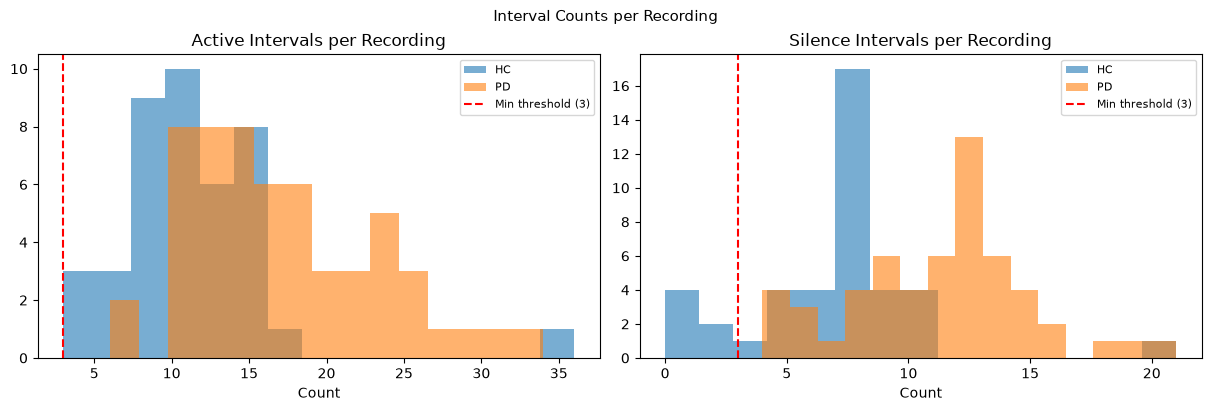

--- SEGMENTATION LIMITATIONS AND EXPECTED IMPACT ---

1. TKEO vs IAIF:
   TKEO detects broadband energy bursts. IAIF (LP residual) detects voicing state.
   For /pa/ and /ta/, plosive bursts dominate — TKEO is a reasonable approximation.
   For mixed-voicing speech, TKEO may merge or split syllables incorrectly.

2. Recording duration (~5 s):
   At ~4 Hz DDK rate, ~20 intervals per recording. Skewness/kurtosis need >= 4.
   Normality test needs >= 8 — may be unavailable for some recordings.

3. Threshold sensitivity:
   TKEO threshold = 15th percentile. Quiet or noisy recordings may
   produce over- or under-segmentation.

4. JSD with small HC reference:
   HC reference pooled from 395 active intervals (33 recordings).
   Small samples → noisy histograms → unstable JSD values.

5. No /pataka/:
   Paper analyses multisyllabic /pataka/. Our dataset has only /pa/ and /ta/.
   Multisyllabic analysis cannot be reproduced.

6. 10 test groups:
   All held-out metrics are estimates with very h

In [ ]:
# Segmentation error analysis and documented limitations

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, col, title in zip(axes, ['n_active', 'n_silence'],
                            ['Active Intervals per Recording', 'Silence Intervals per Recording']):
    for lname, subset in syllabic_df.groupby('label_name'):
        ax.hist(subset[col].dropna().astype(int), alpha=0.6, bins=15, label=lname)
    ax.axvline(MIN_ACTIVE_INTERVALS, color='red', ls='--', label=f'Min threshold ({MIN_ACTIVE_INTERVALS})')
    ax.set_title(title); ax.set_xlabel('Count'); ax.legend(fontsize=8)
plt.suptitle('Interval Counts per Recording', fontsize=11)
plt.show()

print()

In [ ]:
print()

fmt = lambda v: f'{v:.4f}' if isinstance(v, float) else str(v)
print(f'Syllabic RF — recording accuracy:  {fmt(test_metrics.get("accuracy", "N/A"))}')
print(f'Baseline RF — recording accuracy:  {fmt(base_rec.get("accuracy", "N/A"))}')
print(f'Syllabic RF — recording ROC-AUC:   {fmt(test_metrics.get("roc_auc", "N/A"))}')
print(f'Baseline RF — recording ROC-AUC:   {fmt(base_rec.get("roc_auc", "N/A"))}')
print()


CONCLUSION — SYLLABIC INTERVAL ANALYSIS (PAPER-INSPIRED EXPERIMENTAL)

Paper: Gómez-Vilda et al., BIOSIGNALS 2021
Segmentation: TKEO (not IAIF) — documented approximation for /pa/ and /ta/

Syllabic RF — recording accuracy:  1.0000
Baseline RF — recording accuracy:  1.0000
Syllabic RF — recording ROC-AUC:   1.0000
Baseline RF — recording ROC-AUC:   1.0000



---

# Personal Voice Testing (Inference Only)

> **MANDATORY DISCLAIMERS:**
> 
> - This section is **inference-only**. Personal recordings are **never** used for training,
>   cross-validation, feature selection, HC reference construction, or any reported metric.
> - Outputs are **experimental model predictions only — NOT medical diagnoses**.
> - The PD probability shown does **NOT** represent the user's actual probability of having PD.
> - The model was trained on 22 Italian elderly HC + 28 PD participants using 5-second DDK
>   recordings. It cannot reliably generalise to other populations, languages, or recording
>   conditions.
> - If the model has not been trained and saved (Cell 20), this section will raise an error.

Expected recording paths:
- `data/personal_ddk/DDK001-pa.wav`
- `data/personal_ddk/DDK001-ta.wav`

In [ ]:
#Load saved model and HC reference for inference

if not model_output_path.is_file():
    raise FileNotFoundError(
        f'Trained syllabic model not found: {model_output_path}\n'
        'Run all research evaluation cells (up to Cell 20) first.'
    )
if not hc_reference_path.is_file():
    raise FileNotFoundError(
        f'HC reference bundle not found: {hc_reference_path}\n'
        'Run all research evaluation cells (up to Cell 14) first.'
    )

inf_bundle   = joblib.load(model_output_path)
inf_model    = inf_bundle['model']
inf_features = inf_bundle['feature_names']

ref_bundle  = joblib.load(hc_reference_path)
p_ref_ah    = ref_bundle['ref_active_hist']
p_ref_ae    = ref_bundle['ref_active_edges']
p_ref_sh    = ref_bundle['ref_silence_hist']
p_ref_se    = ref_bundle['ref_silence_edges']

if list(inf_features) != list(FINAL_FEATURE_NAMES):
    raise ValueError(
        f'Feature name mismatch:\n  Loaded: {list(inf_features)}\n  Notebook: {list(FINAL_FEATURE_NAMES)}'
    )

print('Syllabic model and HC reference loaded.')
print(f'  Model: {type(inf_model).__name__}')
print(f'  Features ({len(inf_features)}): {list(inf_features)}')
print(f'  HC reference source: {ref_bundle["source"]}')

Syllabic model and HC reference loaded.
  Model: RandomForestClassifier
  Features (19): ['n_active', 'active_mean', 'active_std', 'active_skew', 'active_kurt', 'active_normaltest_stat', 'active_normaltest_p', 'n_silence', 'silence_mean', 'silence_std', 'silence_skew', 'silence_kurt', 'silence_normaltest_stat', 'silence_normaltest_p', 'active_ratio', 'cv_active', 'cv_silence', 'jsd_active', 'jsd_silence']
  HC reference source: training HC participants only (no leakage)


In [ ]:
# Cell 24: Personal recording inference

PERSONAL_DIR.mkdir(parents=True, exist_ok=True)

personal_paths = sorted(PERSONAL_DDK_DIR.glob('*.wav'))
if not personal_paths:
    raise FileNotFoundError(f'No WAV files found in {PERSONAL_DDK_DIR}')

print(f'Found {len(personal_paths)} personal recording(s):')
for p in personal_paths:
    print(f'  {p.name} ({p.stat().st_size} bytes)')
print()

inf_rows, inf_errors = [], []

for p_path in personal_paths:
    print(f'Processing: {p_path.name}')
    sl = p_path.stem.lower()
    task_lbl = 'D1/pa' if sl.endswith('-pa') else ('D2/ta' if sl.endswith('-ta') else 'unknown')

    try:
        p_feats = extract_syllabic_features(str(p_path))
    except Exception as exc:
        inf_errors.append({'filename': p_path.name, 'error': str(exc)})
        print(f'  ERROR: {exc}'); continue

    if p_feats is None:
        inf_errors.append({'filename': p_path.name,
                            'error': f'Too few active intervals (< {MIN_ACTIVE_INTERVALS})'})
        print('  Too few intervals — skipping.'); continue

    # Compute JSD against training-derived reference (no research data used)
    y_p, sr_p = librosa.load(str(p_path), sr=None, mono=True)
    act_p, sil_p, _, _ = segment_by_tkeo(y_p, sr_p)
    p_feats['jsd_active']  = compute_jsd_vs_reference([e-s for s,e in act_p], p_ref_ah, p_ref_ae)
    p_feats['jsd_silence'] = compute_jsd_vs_reference([e-s for s,e in sil_p], p_ref_sh, p_ref_se)

    feat_vec = pd.DataFrame([{n: p_feats.get(n, np.nan) for n in inf_features}], columns=inf_features)

    # Check and impute any non-finite features
    bad_feats = [n for n in inf_features
                 if pd.isna(feat_vec[n].iloc[0]) or not np.isfinite(feat_vec[n].iloc[0])]
    if bad_feats:
        print(f'  Non-finite features: {bad_feats} — imputing with training median')
        for n in bad_feats:
            feat_vec[n] = float(train_valid[n].median())

    pred_class  = int(inf_model.predict(feat_vec)[0])
    pred_prob   = inf_model.predict_proba(feat_vec)[0]
    pd_prob     = float(pred_prob[1])

    inf_rows.append({
        'filename': p_path.name, 'task': task_lbl,
        'predicted_class': 'PD' if pred_class == 1 else 'HC',
        'pd_probability': pd_prob, 'hc_probability': float(pred_prob[0]),
        'n_active': int(p_feats.get('n_active', -1)),
        'n_silence': int(p_feats.get('n_silence', -1)),
        'jsd_active': float(p_feats.get('jsd_active', np.nan)),
        'jsd_silence': float(p_feats.get('jsd_silence', np.nan)),
        'imputed_features': bad_feats,
    })
    print(f'  Task: {task_lbl} | Prediction: {"PD" if pred_class==1 else "HC"} | PD prob: {pd_prob:.4f}')

if inf_rows:
    inf_df = pd.DataFrame(inf_rows)
    print('\n=== PERSONAL VOICE INFERENCE RESULTS (Syllabic Model) ===')
    display(inf_df[['filename','task','predicted_class','pd_probability','hc_probability',
                    'n_active','n_silence','jsd_active','jsd_silence']])
    print(f'\nMean PD probability: {inf_df["pd_probability"].mean():.4f}')
    print('(Descriptive summary only — not an aggregated medical score.)')
    inf_out = PERSONAL_DIR / 'DDK001_syllabic_inference.csv'
    inf_df.to_csv(inf_out, index=False)
    print('Personal inference saved:', inf_out)
else:
    print('No inference results produced.')
    if inf_errors:
        print('Errors:', inf_errors)

print()


Found 2 personal recording(s):
  DDK001-pa.wav (13324 bytes)
  DDK001-ta.wav (13827 bytes)

Processing: DDK001-pa.wav
  Non-finite features: ['active_normaltest_stat', 'active_normaltest_p', 'silence_skew', 'silence_kurt', 'silence_normaltest_stat', 'silence_normaltest_p'] — imputing with training median
  Task: D1/pa | Prediction: HC | PD prob: 0.1633
Processing: DDK001-ta.wav
  Non-finite features: ['silence_normaltest_stat', 'silence_normaltest_p'] — imputing with training median
  Task: D2/ta | Prediction: HC | PD prob: 0.1133

=== PERSONAL VOICE INFERENCE RESULTS (Syllabic Model) ===


,filename,task,predicted_class,pd_probability,hc_probability,n_active,n_silence,jsd_active,jsd_silence
0,DDK001-pa.wav,D1/pa,HC,0.163333,0.836667,7,3,0.539314,0.625363
1,DDK001-ta.wav,D2/ta,HC,0.113333,0.886667,9,5,0.497858,0.655972



Mean PD probability: 0.1383
(Descriptive summary only — not an aggregated medical score.)
Personal inference saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\personal_inference\DDK001_syllabic_inference.csv

MANDATORY DISCLAIMER
These outputs are EXPERIMENTAL MODEL PREDICTIONS ONLY.
They are NOT medical diagnoses.

The model was trained on a small Italian elderly dataset
(22 HC + 28 PD). It cannot reliably generalise to other
speakers, languages, or recording conditions.

The PD probability does NOT represent the user's actual
probability of having Parkinson's disease.

Personal recordings were NOT used in training, evaluation,
reference construction, or any research metric.


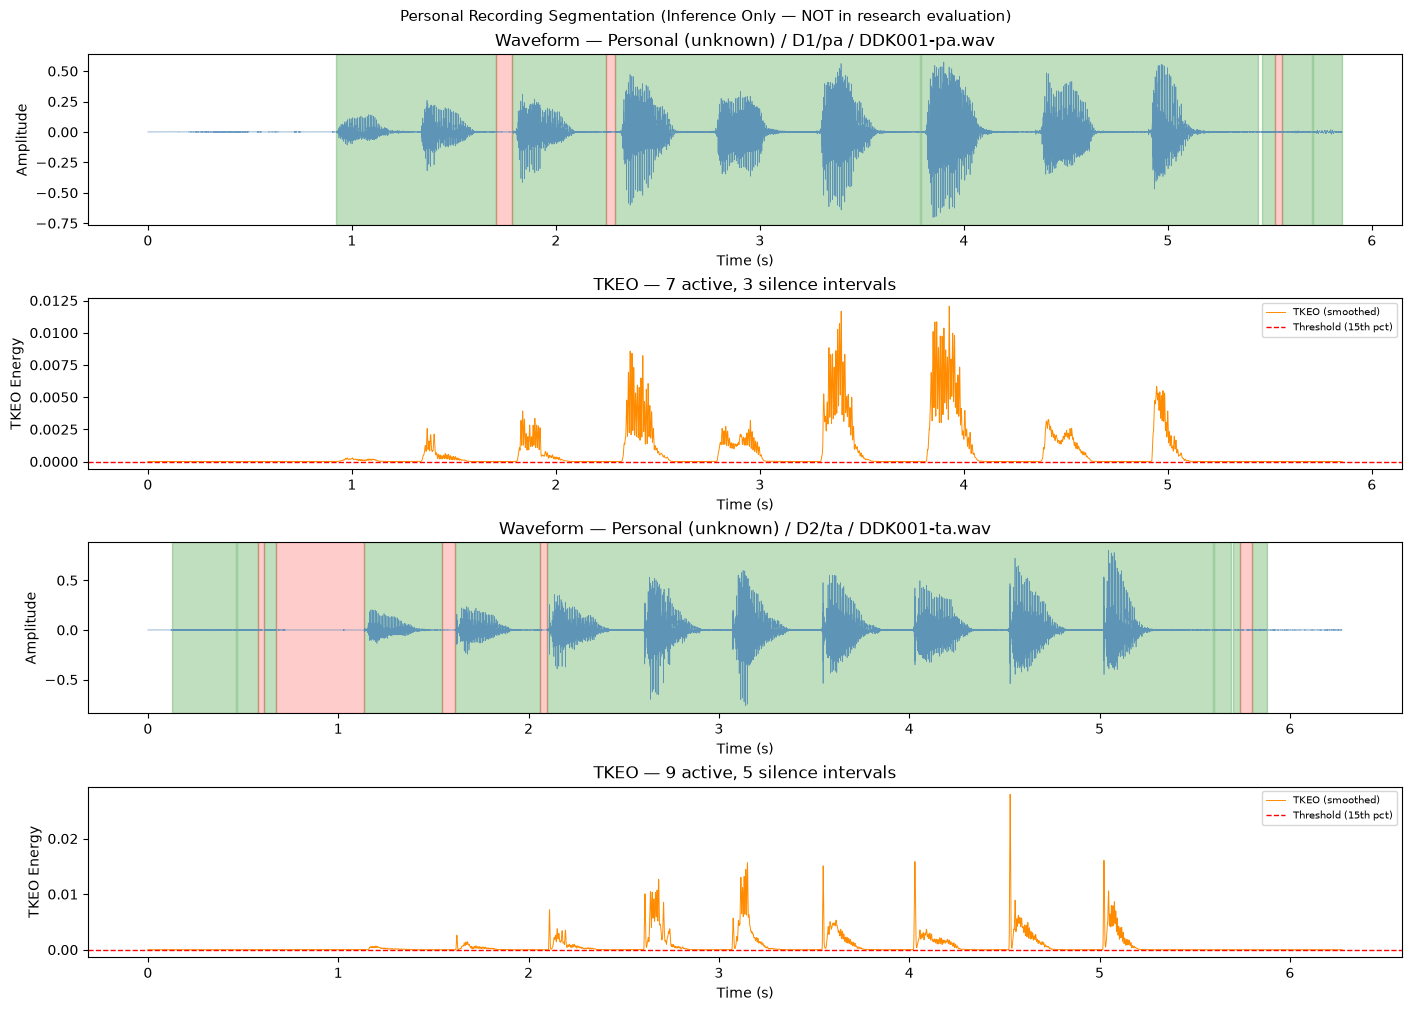

Personal segmentation saved: D:\Projects\KND_CDAP_SE_01\parkinson-speech-ai\results\component3_ddk\paper_inspired_syllabic\personal_inference\personal_segmentation.png


In [25]:
# ---------------------------------------------------------------------------
# Cell 25: Personal recording segmentation visualisation (inference only)
# ---------------------------------------------------------------------------

p_paths_found = sorted(PERSONAL_DDK_DIR.glob('*.wav'))
if p_paths_found:
    n_rec = len(p_paths_found)
    fig, ax_arr = plt.subplots(n_rec * 2, 1, figsize=(14, 5 * n_rec), constrained_layout=True)
    if n_rec == 1:
        ax_arr = np.expand_dims(ax_arr, 0)
    for idx, p_path in enumerate(p_paths_found):
        sl = p_path.stem.lower()
        tlbl = 'D1/pa' if sl.endswith('-pa') else ('D2/ta' if sl.endswith('-ta') else '?')
        _ = visualise_segmentation(p_path, 'Personal (unknown)', tlbl,
                                    [ax_arr[idx*2], ax_arr[idx*2+1]])
    plt.suptitle('Personal Recording Segmentation (Inference Only — NOT in research evaluation)',
                  fontsize=11)
    plt.show()
    sp = PERSONAL_DIR / 'personal_segmentation.png'
    fig.savefig(sp, dpi=100, bbox_inches='tight')
    print('Personal segmentation saved:', sp)
else:
    print('No personal recordings found for visualisation.')